# Studi Kasus Beginner: Penjualan TokoKita 2025

Soal lengkap ada di `../README.md`. Data bersifat **sintetis**.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)

## 1. Load & kenali data

In [2]:
raw = pd.read_csv(BASE / "data" / "penjualan_tokokita_raw.csv")
print("Ukuran data:", raw.shape)
print(raw.dtypes)
print("\nMissing value:\n", raw.isna().sum())
print("\nBaris duplikat:", raw.duplicated().sum())
print("\nVariasi penulisan kota:", raw["kota"].nunique())

Ukuran data: (1225, 9)
order_id             str
tanggal              str
kota                 str
kategori             str
produk               str
jumlah           float64
harga_satuan       int64
diskon_persen      int64
metode_bayar         str
dtype: object

Missing value:
 order_id          0
tanggal           0
kota             25
kategori          0
produk            0
jumlah           15
harga_satuan      0
diskon_persen     0
metode_bayar     30
dtype: int64

Baris duplikat: 25

Variasi penulisan kota: 15


## 2. Data cleaning

In [3]:
df = raw.drop_duplicates().copy()
df["kota"] = df["kota"].str.strip().str.title().fillna("Tidak Diketahui")
df["metode_bayar"] = df["metode_bayar"].fillna("Tidak Diketahui")
df = df.dropna(subset=["jumlah"])  # tanpa jumlah, pendapatan tidak bisa dihitung
df["jumlah"] = df["jumlah"].astype(int)
df["tanggal"] = pd.to_datetime(df["tanggal"])
df["bulan"] = df["tanggal"].dt.strftime("%Y-%m")
df["pendapatan"] = df["jumlah"] * df["harga_satuan"] * (100 - df["diskon_persen"]) // 100
df.to_csv(OUT / "penjualan_clean.csv", index=False)
print(f"\nBaris sebelum: {len(raw)}, sesudah cleaning: {len(df)}")


Baris sebelum: 1225, sesudah cleaning: 1185


## 3. KPI utama

In [4]:
total = df["pendapatan"].sum()
order = df["order_id"].nunique()
print(f"Total pendapatan : Rp{total:,.0f}")
print(f"Jumlah order     : {order:,}")
print(f"Unit terjual     : {df['jumlah'].sum():,}")
print(f"Rata-rata/order  : Rp{total / order:,.0f}")

Total pendapatan : Rp536,737,000
Jumlah order     : 1,185
Unit terjual     : 2,332
Rata-rata/order  : Rp452,943


## 4. Pendapatan per bulan

In [5]:
bulanan = df.groupby("bulan")["pendapatan"].sum()
print(bulanan)

bulan
2025-01    39204500
2025-02    42742250
2025-03    54458750
2025-04    34415250
2025-05    35767750
2025-06    44538750
2025-07    44704500
2025-08    41069750
2025-09    38733000
2025-10    39471500
2025-11    61325750
2025-12    60305250
Name: pendapatan, dtype: int64


## 5. Kategori

In [6]:
kategori = (df.groupby("kategori")
              .agg(order=("order_id", "count"), unit=("jumlah", "sum"),
                   pendapatan=("pendapatan", "sum"))
              .sort_values("pendapatan", ascending=False))
kategori["kontribusi_%"] = (kategori["pendapatan"] / total * 100).round(1)
print(kategori)

              order  unit  pendapatan  kontribusi_%
kategori                                           
Fashion         435   874   205998250          38.4
Elektronik      308   602   184554500          34.4
Rumah Tangga    227   448    96934000          18.1
Kecantikan      215   408    49250250           9.2


## 6. Top 5 produk

In [7]:
top_produk = df.groupby("produk")["pendapatan"].sum().nlargest(5)
print(top_produk)

produk
Sepatu        118293750
Smartwatch    107380000
Jaket          65587500
Blender        55408000
Power Bank     49687000
Name: pendapatan, dtype: int64


## 7. Kota

In [8]:
kota = (df.groupby("kota")
          .agg(order=("order_id", "count"), pendapatan=("pendapatan", "sum"))
          .sort_values("pendapatan", ascending=False))
kota["rata_per_order"] = (kota["pendapatan"] / kota["order"]).round(0)
print(kota)

                 order  pendapatan  rata_per_order
kota                                              
Jakarta            378   175306000        463772.0
Surabaya           255   109756250        430417.0
Bandung            231   101574500        439716.0
Medan              171    84219500        492512.0
Makassar           125    50378250        403026.0
Tidak Diketahui     25    15502500        620100.0


## 8. Metode pembayaran

In [9]:
bayar = df["metode_bayar"].value_counts().to_frame("order")
bayar["persen"] = (bayar["order"] / len(df) * 100).round(1)
print(bayar)

                 order  persen
metode_bayar                  
E-Wallet           441    37.2
Transfer Bank      368    31.1
COD                224    18.9
Kartu Kredit       122    10.3
Tidak Diketahui     30     2.5


## 9. Visualisasi

Grafik tersimpan di folder output/


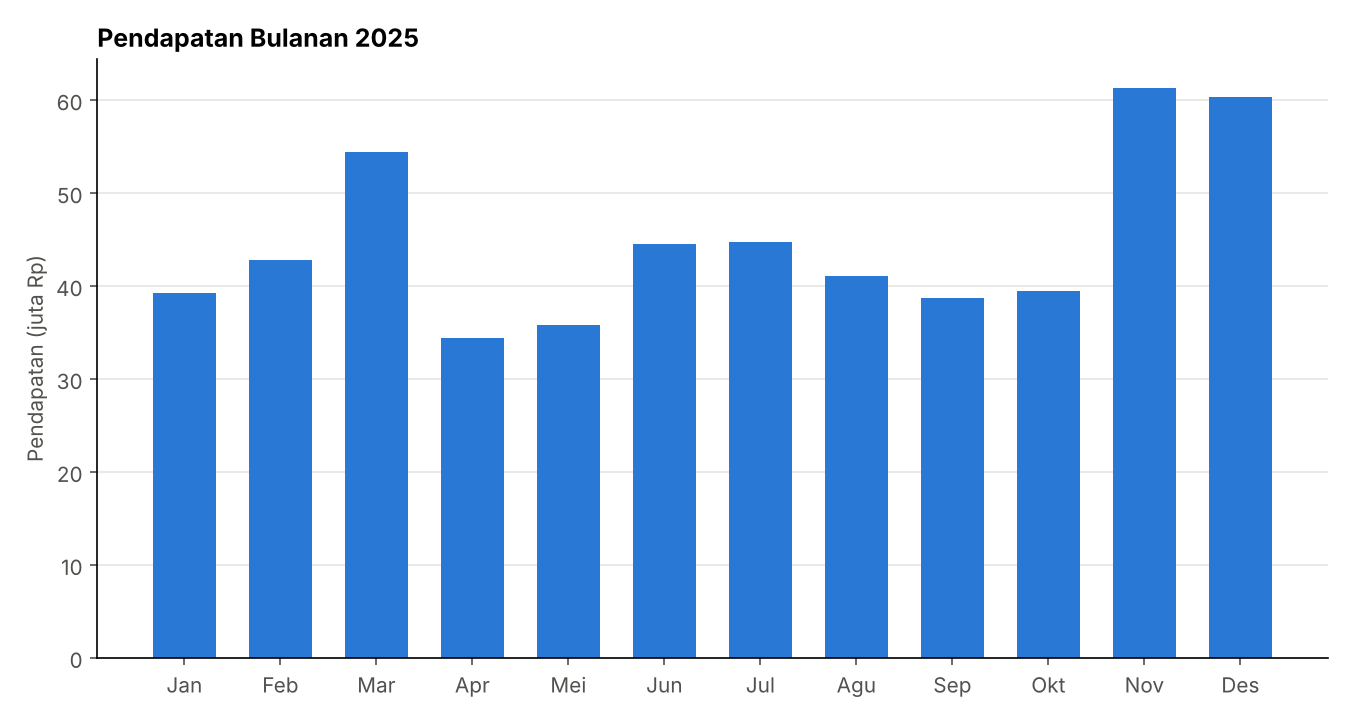

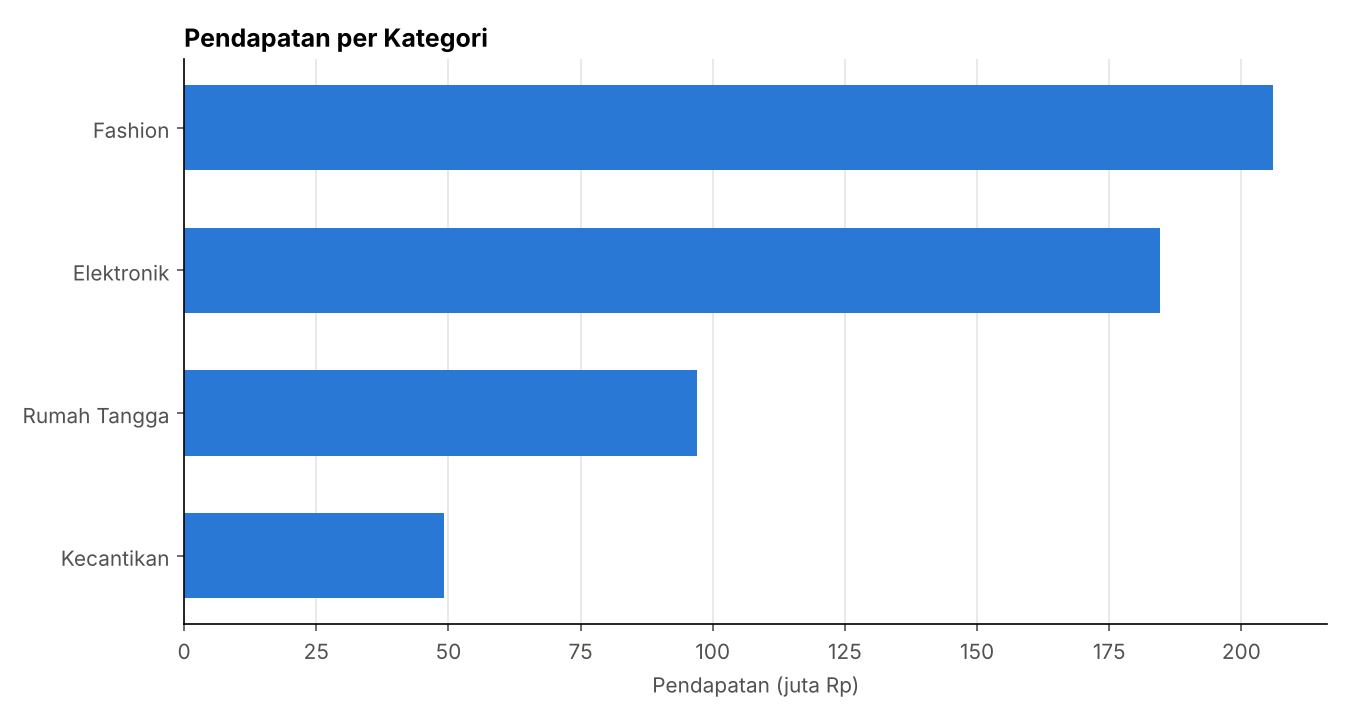

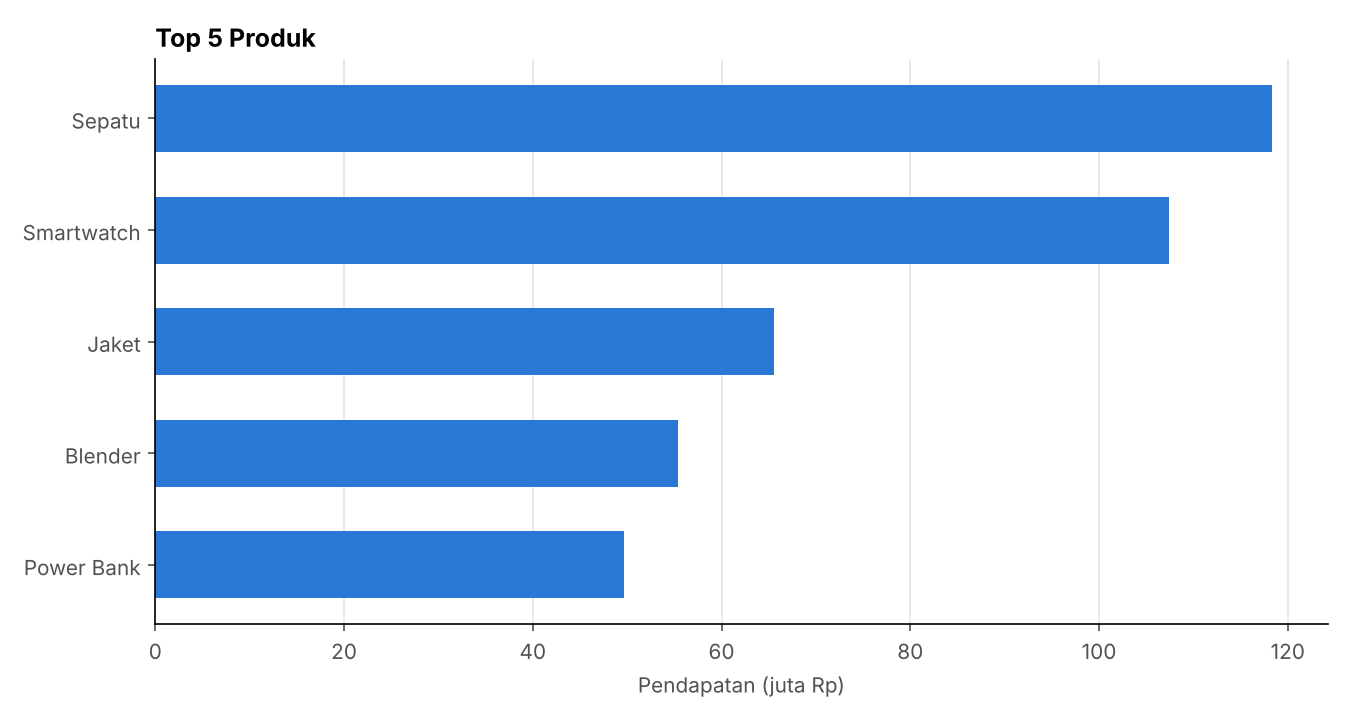

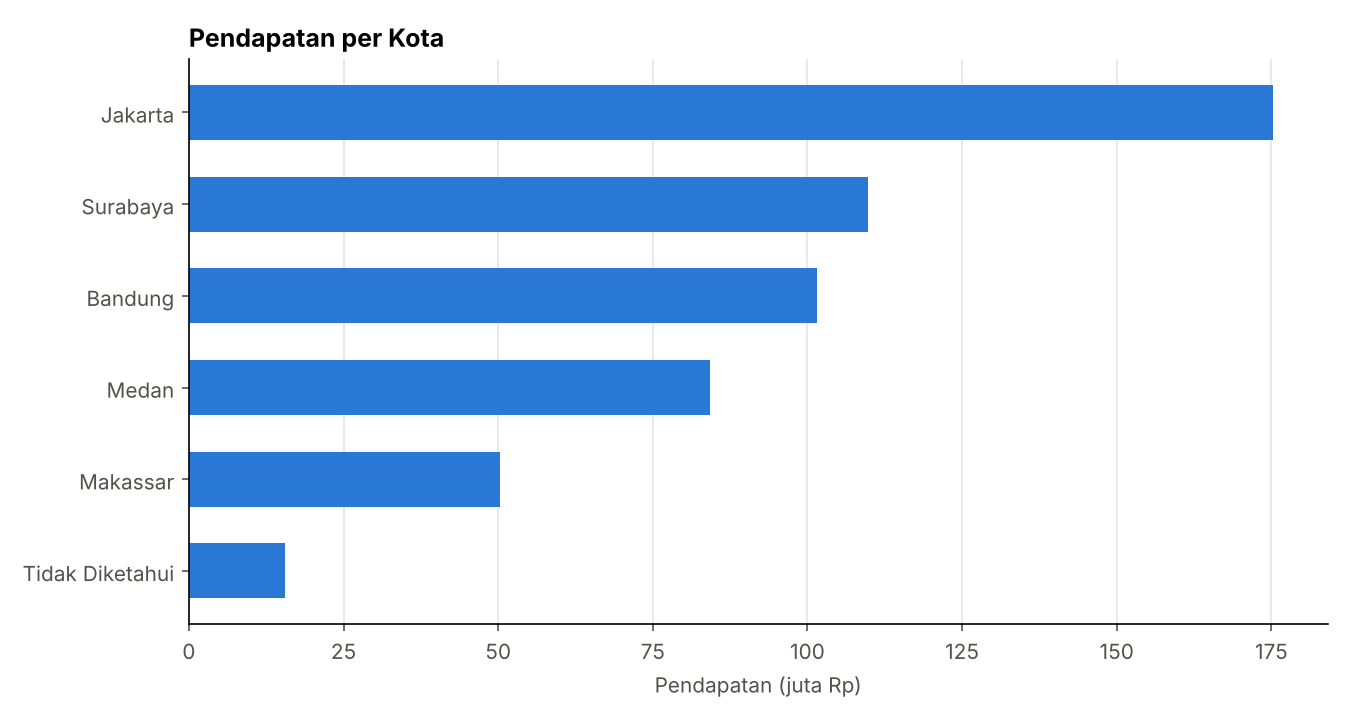

In [10]:
BIRU, TINTA = "#2a78d6", "#52514e"
juta = FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}")

def simpan(seri, judul, nama, horizontal=True):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    if horizontal:
        s = seri.sort_values()
        ax.barh(s.index, s.values, color=BIRU, height=0.6)
        ax.xaxis.set_major_formatter(juta)
        ax.set_xlabel("Pendapatan (juta Rp)", color=TINTA)
        ax.grid(axis="x", color="#e6e5e0")
    else:
        ax.bar(seri.index, seri.values, color=BIRU, width=0.65)
        ax.yaxis.set_major_formatter(juta)
        ax.set_ylabel("Pendapatan (juta Rp)", color=TINTA)
        ax.set_xticks(range(len(seri)),
                      ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
                       "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
        ax.grid(axis="y", color="#e6e5e0")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=TINTA)
    ax.set_title(judul, loc="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT / nama, dpi=150)
    plt.close(fig)

simpan(bulanan, "Pendapatan Bulanan 2025", "01_pendapatan_bulanan.png", horizontal=False)
simpan(kategori["pendapatan"], "Pendapatan per Kategori", "02_kategori.png")
simpan(top_produk, "Top 5 Produk", "03_top_produk.png")
simpan(kota["pendapatan"], "Pendapatan per Kota", "04_kota.png")
print("Grafik tersimpan di folder output/")

from IPython.display import Image, display
for f in sorted(OUT.glob("*.png")):
    display(Image(filename=str(f)))